# Nice Rooms: a 5, 10 and 15 year projection

The panel covers two years. This notebook carries the last complete year forward
to 2033, 2038 and 2043 under three scenarios, and states every assumption that
does the work. It answers four questions: what the portfolio earns at each
horizon, how wide the uncertainty is, which driver moves the value, and which
hotels compound fastest.

This is a scenario model, not a forecast. There is no new supply, no renovation
programme beyond a capital reserve, no debt and no terminal sale cost. Fifteen
years is more than seven times the observed window, so treat the year 15 column
as the arithmetic of the assumptions, not as a prediction.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})


def data_dir() -> Path:
    """The folder holding the JSON Lines files, on Kaggle or beside them."""
    for base in (
        Path("/kaggle/input/nice-rooms-hotel-revenue-rate-intelligence"),
        Path("."),
        Path("data/nice-rooms-kaggle"),
        Path("../data/nice-rooms-kaggle"),
    ):
        if (base / "hotels.jsonl").exists():
            return base
    found = list(Path("/kaggle/input").rglob("hotels.jsonl"))
    if found:
        return found[0].parent
    listing = sorted(str(path) for path in Path("/kaggle/input").rglob("*"))
    raise FileNotFoundError("hotels.jsonl not found; /kaggle/input holds " + repr(listing[:20]))


def load(name: str) -> pd.DataFrame:
    return pd.read_json(data_dir() / name, lines=True)


hotels = load("hotels.jsonl")
rooms = load("room_types.jsonl")
daily = load("daily_market.jsonl")
weekly = load("weekly_performance.jsonl")
decisions = load("rate_decisions.jsonl")
reviews = load("reviews.jsonl")
scenarios = load("review_scenarios.jsonl")

daily["date"] = pd.to_datetime(daily["date"])
weekly["week_start"] = pd.to_datetime(weekly["week_start"])
reviews["review_date"] = pd.to_datetime(reviews["review_date"])
reviews["stay_date"] = pd.to_datetime(reviews["stay_date"])
daily["month"] = daily["date"].dt.to_period("M").astype(str)
weekly["month"] = weekly["week_start"].dt.to_period("M").astype(str)


## The base year

Everything starts from 2028, the last complete year in `weekly_performance.jsonl`.
Occupancy is the year's rooms sold over rooms available. ADR is room revenue
over rooms sold, so package and discount business is already inside it. The
stabilised occupancy blends the base year with the two year mean, because a
single year can be flattered by one strong season.

The rating edge is the hotel's lifetime rating against its tier mean. It enters
as a small ADR growth premium, capped at 75 basis points a year, so a strong
review position compounds gently and a weak one is not punished twice.

The starting rate is what the hotels actually achieved, not a forecast: across
the panel the median night sits within about five percent of MARS, so the base
year is a defensible level rather than an optimistic one.


In [2]:
BASE_YEAR = 2028
HORIZONS = (5, 10, 15)
HORIZON = max(HORIZONS)

last_year = weekly[weekly["week_start"].dt.year == BASE_YEAR]
base = last_year.groupby("hotel_id").agg(
    room_revenue=("room_revenue", "sum"),
    ancillary_revenue=("ancillary_revenue", "sum"),
    total_revenue=("total_revenue", "sum"),
    gop=("gross_operating_profit", "sum"),
    rooms_sold=("rooms_sold", "sum"),
    available_rooms=("available_rooms", "sum"),
)
base["adr"] = base["room_revenue"] / base["rooms_sold"]
base["occupancy"] = base["rooms_sold"] / base["available_rooms"]
base["revpar"] = base["room_revenue"] / base["available_rooms"]
base["ancillary_ratio"] = base["ancillary_revenue"] / base["room_revenue"]
base["gop_margin"] = base["gop"] / base["total_revenue"]

whole = weekly.groupby("hotel_id")[["rooms_sold", "available_rooms"]].sum()
base["start_occupancy"] = (0.65 * base["occupancy"]
                           + 0.35 * whole["rooms_sold"] / whole["available_rooms"])

base = base.join(hotels.set_index("hotel_id")[["name", "tier", "rooms", "lifetime_rating"]])
base["tier_mean_rating"] = base.groupby("tier")["lifetime_rating"].transform("mean")
base["rating_edge"] = (base["lifetime_rating"] - base["tier_mean_rating"]).clip(-1.2, 1.2)

print(str(len(base)) + " hotels, " + format(int(base["rooms"].sum()), ",") + " rooms, base year "
      + str(BASE_YEAR) + ", " + format(int(base["total_revenue"].sum()), ",") + " USD total revenue")
base.assign(
    occupancy=base["occupancy"].round(3),
    adr=base["adr"].round(2),
    revpar=base["revpar"].round(2),
    gop_margin=base["gop_margin"].round(3),
)[["name", "tier", "rooms", "occupancy", "adr", "revpar", "gop_margin", "lifetime_rating"]]


14 hotels, 1,760 rooms, base year 2028, 117,948,653 USD total revenue


,name,tier,rooms,occupancy,adr,revpar,gop_margin,lifetime_rating
hotel_id,,,,,,,,
H01,Alder & Quay Hotel,upscale,168,0.739,233.56,172.62,0.295,3.510
H02,The Lantern House,boutique,54,0.757,264.31,200.01,0.324,3.450
H03,Marisol Bay Resort,luxury,212,0.728,394.95,287.62,0.346,3.549
H04,Harborlight Suites,upscale,140,0.750,251.62,188.59,0.284,3.325
H05,The Copper Meridian,luxury,96,0.718,356.94,256.35,0.335,3.569
H06,Seabright Grand,upscale,240,0.728,219.76,159.90,0.270,3.317
H07,The Wren Rooms,boutique,38,0.768,199.79,153.47,0.306,3.128
H08,Northgate Inn,economy,120,0.634,98.50,62.48,0.222,2.942
H09,Cedar & Salt Hotel,midscale,150,0.677,148.12,100.29,0.243,3.210


## Assumptions in one place

| Assumption | Value | Why |
| --- | ---: | --- |
| Inflation | 2.5% a year | deflates the real columns |
| Discount rate | 9.0% | owner's cost of capital for a hold and exit view |
| ADR growth, base | 3.0% a year | inflation plus a thin real gain |
| Occupancy drift, base | 0.0 points | 2028 is already at the two year mean |
| GOP margin gain | 2.0 points over 10 years | operating leverage on fixed cost |
| Cap rate, base | 7.5% | stabilised waterfront and city hotels |
| Management fee plus fixed charges | 4.0% of revenue | below GOP, above NOI |
| Capital reserve | 3.0% of revenue | furniture, fixtures and equipment |

The downside moves ADR growth to 2.0%, occupancy down 6 points and the cap rate
to 8.5%. The upside moves ADR growth to 4.2%, occupancy up 2.5 points, margin
gain to 3 points and the cap rate to 6.8%. Occupancy is floored at 45% and
capped at 94%, the practical ceiling once maintenance rooms are excluded.


In [3]:
ASSUMPTIONS = {
    "base_year": BASE_YEAR,
    "horizon_years": HORIZON,
    "inflation": 0.025,
    "discount_rate": 0.09,
    "rating_link": 0.0025,
    "rating_link_cap": 0.0075,
    "occupancy_floor": 0.45,
    "occupancy_ceiling": 0.94,
    "ramp_years": 3,
    "management_fee": 0.030,
    "fixed_charges": 0.010,
    "capex_reserve": 0.030,
    "leverage_years": 10,
    "scenarios": {
        "downside": {"adr_growth": 0.020, "occupancy_drift": -0.060,
                     "margin_gain": 0.000, "cap_rate": 0.085},
        "base": {"adr_growth": 0.030, "occupancy_drift": 0.000,
                 "margin_gain": 0.002, "cap_rate": 0.075},
        "upside": {"adr_growth": 0.042, "occupancy_drift": 0.025,
                   "margin_gain": 0.003, "cap_rate": 0.068},
    },
}

view = pd.DataFrame(ASSUMPTIONS["scenarios"]).T
view["inflation"] = ASSUMPTIONS["inflation"]
view["discount_rate"] = ASSUMPTIONS["discount_rate"]
view.round(3)


,adr_growth,occupancy_drift,margin_gain,cap_rate,inflation,discount_rate
downside,0.020,-0.060,0.000,0.085,0.025,0.09
base,0.030,0.000,0.002,0.075,0.025,0.09
upside,0.042,0.025,0.003,0.068,0.025,0.09


## The projection engine

One function, one row per hotel-year, no randomness. Every column is derived from the base year and the scenario block above, so a reviewer can follow a single line from ADR to value.


In [4]:
def project(growth: float, occupancy_drift: float, margin_gain: float, cap_rate: float,
            years: int = HORIZON) -> pd.DataFrame:
    """One scenario, every hotel, every year. One row per hotel-year.

    ADR compounds from the base year, occupancy ramps to its stabilised level over
    three years, the GOP margin gains operating leverage for ten years, and value
    is NOI less a capital reserve, capitalised at the scenario cap rate.
    """
    quality = (base["rating_edge"] * ASSUMPTIONS["rating_link"]).clip(
        -ASSUMPTIONS["rating_link_cap"], ASSUMPTIONS["rating_link_cap"])
    fee = ASSUMPTIONS["management_fee"] + ASSUMPTIONS["fixed_charges"]
    reserve = ASSUMPTIONS["capex_reserve"]
    blocks = []
    for year_index in range(1, years + 1):
        ramp = min(year_index, ASSUMPTIONS["ramp_years"]) / ASSUMPTIONS["ramp_years"]
        adr = base["adr"] * (1.0 + growth + quality) ** year_index
        occupancy = (base["start_occupancy"] + occupancy_drift * ramp).clip(
            ASSUMPTIONS["occupancy_floor"], ASSUMPTIONS["occupancy_ceiling"])
        room_revenue = base["rooms"] * 365 * occupancy * adr
        total_revenue = room_revenue * (1.0 + base["ancillary_ratio"])
        margin = (base["gop_margin"]
                  + margin_gain * min(year_index, ASSUMPTIONS["leverage_years"])).clip(0.05, 0.60)
        gop = total_revenue * margin
        noi = gop - fee * total_revenue
        value = (noi - reserve * total_revenue) / cap_rate
        blocks.append(pd.DataFrame({
            "year_index": year_index,
            "calendar_year": BASE_YEAR + year_index,
            "hotel_id": base.index,
            "tier": base["tier"].to_numpy(),
            "rooms": base["rooms"].to_numpy(),
            "room_nights": (base["rooms"] * 365 * occupancy).to_numpy(),
            "occupancy": occupancy.to_numpy(),
            "adr": adr.to_numpy(),
            "revpar": (occupancy * adr).to_numpy(),
            "room_revenue": room_revenue.to_numpy(),
            "total_revenue": total_revenue.to_numpy(),
            "gop": gop.to_numpy(),
            "gop_margin": margin.to_numpy(),
            "noi": noi.to_numpy(),
            "value": value.to_numpy(),
            "value_per_room": (value / base["rooms"]).to_numpy(),
        }))
    return pd.concat(blocks, ignore_index=True)


In [5]:
frames = []
for name, plan in ASSUMPTIONS["scenarios"].items():
    frame = project(
        growth=plan["adr_growth"],
        occupancy_drift=plan["occupancy_drift"],
        margin_gain=plan["margin_gain"],
        cap_rate=plan["cap_rate"],
    )
    frame["scenario"] = name
    frames.append(frame)

projection = pd.concat(frames, ignore_index=True)
projection["value_real"] = projection["value"] / (1 + ASSUMPTIONS["inflation"]) ** projection["year_index"]
projection["value_pv"] = projection["value"] / (1 + ASSUMPTIONS["discount_rate"]) ** projection["year_index"]
projection = projection[[
    "scenario", "year_index", "calendar_year", "hotel_id", "tier", "rooms", "room_nights",
    "occupancy", "adr", "revpar", "room_revenue", "total_revenue", "gop", "gop_margin",
    "noi", "value", "value_real", "value_pv", "value_per_room",
]]

print(str(len(projection)) + " rows, " + str(projection["scenario"].nunique()) + " scenarios, "
      + str(HORIZON) + " years")
projection.head()


630 rows, 3 scenarios, 15 years


,scenario,year_index,calendar_year,hotel_id,tier,rooms,room_nights,occupancy,adr,revpar,room_revenue,total_revenue,gop,gop_margin,noi,value,value_real,value_pv,value_per_room
0,downside,1,2029,H01,upscale,168,44062.830082,0.718572,238.324768,171.253486,1.050126e+07,1.235075e+07,3.647588e+06,0.295333,3.153558e+06,3.274160e+07,3.194302e+07,3.003817e+07,194890.476035
1,downside,1,2029,H02,boutique,54,14522.943887,0.736831,269.678724,198.707711,3.916529e+06,4.600405e+06,1.490267e+06,0.323943,1.306251e+06,1.374399e+07,1.340877e+07,1.260916e+07,254518.245421
2,downside,1,2029,H03,luxury,212,54787.166827,0.708027,402.841715,285.223006,2.207056e+07,2.610748e+07,9.023240e+06,0.345619,7.978941e+06,8.465549e+07,8.259072e+07,7.766558e+07,399318.327729
3,downside,1,2029,H04,upscale,140,37266.876030,0.729293,256.637833,187.164194,9.564090e+06,1.101316e+07,3.124696e+06,0.283724,2.684170e+06,2.769147e+07,2.701607e+07,2.540502e+07,197796.227696
4,downside,1,2029,H05,luxury,96,24473.621016,0.698448,364.089551,254.297651,8.910590e+06,1.056357e+07,3.538967e+06,0.335016,3.116425e+06,3.293550e+07,3.213219e+07,3.021605e+07,343078.121187


In [6]:
def portfolio(frame: pd.DataFrame) -> pd.DataFrame:
    """Roll hotel-years up to the portfolio, weighting occupancy by room count."""
    grouped = frame.groupby(["scenario", "year_index"]).agg(
        rooms=("rooms", "sum"),
        room_nights=("room_nights", "sum"),
        room_revenue=("room_revenue", "sum"),
        total_revenue=("total_revenue", "sum"),
        gop=("gop", "sum"),
        noi=("noi", "sum"),
        value=("value", "sum"),
        value_real=("value_real", "sum"),
        value_pv=("value_pv", "sum"),
    )
    grouped["calendar_year"] = BASE_YEAR + grouped.index.get_level_values("year_index")
    grouped["occupancy"] = grouped["room_nights"] / (grouped["rooms"] * 365)
    grouped["adr"] = grouped["room_revenue"] / grouped["room_nights"]
    grouped["revpar"] = grouped["room_revenue"] / (grouped["rooms"] * 365)
    grouped["gop_margin"] = grouped["gop"] / grouped["total_revenue"]
    grouped["value_per_room"] = grouped["value"] / grouped["rooms"]
    return grouped.reset_index()


path = portfolio(projection)
path.head()


,scenario,year_index,rooms,room_nights,room_revenue,total_revenue,gop,noi,value,value_real,value_pv,calendar_year,occupancy,adr,revpar,gop_margin,value_per_room
0,base,1,1760,454263.181662,1.046855e+08,1.218156e+08,3.606468e+07,3.119206e+07,3.671679e+08,3.582126e+08,3.368513e+08,2029,0.707134,230.451114,162.959926,0.296060,208618.113486
1,base,2,1760,454263.181662,1.078268e+08,1.254711e+08,3.739797e+07,3.237912e+07,3.815332e+08,3.631488e+08,3.211289e+08,2030,0.707134,237.366325,167.849910,0.298060,216780.232924
2,base,3,1760,454263.181662,1.110624e+08,1.292362e+08,3.877879e+07,3.360934e+07,3.964301e+08,3.681247e+08,3.061168e+08,2031,0.707134,244.489052,172.886635,0.300061,225244.361405
3,base,4,1760,454263.181662,1.143951e+08,1.331144e+08,4.020882e+07,3.488424e+07,4.118774e+08,3.731406e+08,2.917844e+08,2032,0.707134,251.825520,178.074505,0.302062,234021.274906
4,base,5,1760,454263.181662,1.178278e+08,1.371089e+08,4.168974e+07,3.620539e+07,4.278949e+08,3.781968e+08,2.781024e+08,2033,0.707134,259.382144,183.418054,0.304063,243122.124202


## The three horizons

Revenue, GOP and value are portfolio totals in USD millions, nominal unless the
column says real. `value_real_musd` is in 2028 money. `hold_and_exit_pv_musd`
discounts the operating cash flows to each horizon, adds the projected sale at
that horizon, and is the number to compare with a purchase price today.


In [7]:
def checkpoint(frame: pd.DataFrame) -> pd.DataFrame:
    """The three horizons, with value in nominal, real and present-value terms."""
    rate = ASSUMPTIONS["discount_rate"]
    reserve = ASSUMPTIONS["capex_reserve"]
    rows = []
    for scenario, group in frame.groupby("scenario"):
        yearly = portfolio(group).set_index("year_index")
        cash = yearly["noi"] - reserve * yearly["total_revenue"]
        for year_index in HORIZONS:
            span = yearly.loc[:year_index]
            discounted = float((cash.loc[:year_index] / (1 + rate) ** span.index).sum())
            exit_value = float(yearly.loc[year_index, "value"] / (1 + rate) ** year_index)
            rows.append({
                "scenario": scenario,
                "years_out": year_index,
                "year": BASE_YEAR + year_index,
                "occupancy": yearly.loc[year_index, "occupancy"],
                "adr": yearly.loc[year_index, "adr"],
                "revpar": yearly.loc[year_index, "revpar"],
                "total_revenue_musd": yearly.loc[year_index, "total_revenue"] / 1e6,
                "gop_musd": yearly.loc[year_index, "gop"] / 1e6,
                "value_musd": yearly.loc[year_index, "value"] / 1e6,
                "value_real_musd": yearly.loc[year_index, "value_real"] / 1e6,
                "value_per_room": yearly.loc[year_index, "value_per_room"],
                "hold_and_exit_pv_musd": (discounted + exit_value) / 1e6,
            })
    table = pd.DataFrame(rows)
    table["scenario"] = pd.Categorical(table["scenario"], list(ASSUMPTIONS["scenarios"]), ordered=True)
    return table.sort_values(["scenario", "years_out"]).reset_index(drop=True)


checkpoint(projection).round(2)


,scenario,years_out,year,occupancy,adr,revpar,total_revenue_musd,gop_musd,value_musd,value_real_musd,value_per_room,hold_and_exit_pv_musd
0,downside,5,2033,0.65,247.37,160.08,119.67,35.20,315.59,278.94,179313.95,307.12
1,downside,10,2038,0.65,273.13,176.75,132.13,38.87,348.46,272.22,197989.05,320.95
2,downside,15,2043,0.65,301.57,195.16,145.89,42.92,384.75,265.66,218609.29,330.87
3,base,5,2033,0.71,259.38,183.42,137.11,41.69,427.89,378.20,243122.12,393.15
4,base,10,2038,0.71,300.71,212.64,158.95,49.92,517.27,404.09,293903.57,424.01
5,base,15,2043,0.71,348.61,246.52,184.28,57.88,599.69,414.07,340734.73,439.51
6,upside,5,2033,0.73,274.71,201.12,150.34,46.46,528.47,467.09,300265.89,467.27
7,upside,10,2038,0.73,337.46,247.07,184.69,59.84,689.95,538.98,392014.36,521.21
8,upside,15,2043,0.73,414.55,303.51,226.88,73.52,847.57,585.22,481576.54,549.21


## The RevPAR path

Nominal RevPAR for the portfolio. The three lines share the base year and diverge only through the scenario block.


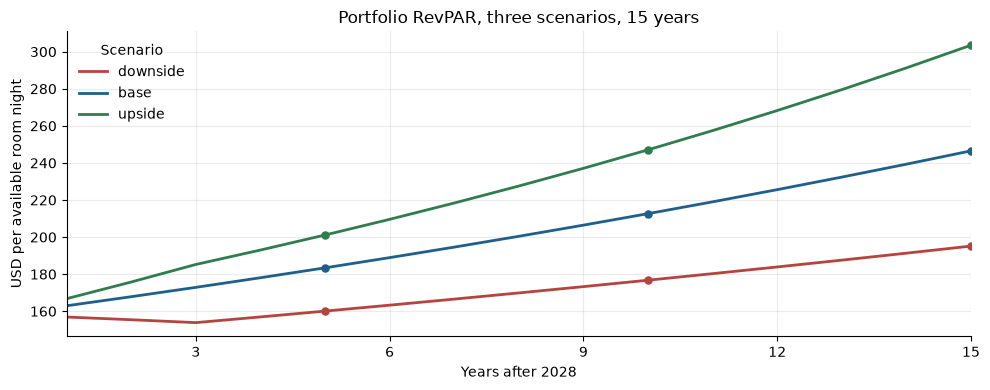

In [8]:
palette = {"downside": "#b5443f", "base": "#1f5f8b", "upside": "#2f7d4f"}

ax = plt.figure(figsize=(10, 4)).add_subplot()
for scenario in ("downside", "base", "upside"):
    series = path[path["scenario"] == scenario].set_index("year_index")["revpar"]
    ax.plot(series.index, series, color=palette[scenario], linewidth=2, label=scenario)
    ax.scatter(HORIZONS, [series.loc[year] for year in HORIZONS],
               color=palette[scenario], s=26, zorder=3)
ax.set_title("Portfolio RevPAR, three scenarios, 15 years")
ax.set_xlabel("Years after " + str(BASE_YEAR))
ax.set_ylabel("USD per available room night")
ax.set_xticks(range(0, HORIZON + 1, 3))
ax.set_xlim(1, HORIZON)
ax.legend(frameon=False, title="Scenario")
plt.tight_layout()
plt.show()


## How wide is the range

The base case is one point on a surface. Five hundred draws vary ADR growth,
occupancy drift and the exit cap rate around the base, and the band below is the
10th to 90th percentile of the resulting portfolio value. The cap rate is the
sharpest single lever: 60 basis points on the exit yield is worth about 8
percent of value, before any operating change.


In [9]:
rng = np.random.default_rng(20271014)
draws = 500
base_plan = ASSUMPTIONS["scenarios"]["base"]

growth = rng.normal(base_plan["adr_growth"], 0.008, draws)
drift = rng.normal(0.020, 0.020, draws)
cap = rng.normal(base_plan["cap_rate"], 0.006, draws)

rooms = base["rooms"].to_numpy(float)
adr0 = base["adr"].to_numpy(float)
occ0 = base["start_occupancy"].to_numpy(float)
ancillary = base["ancillary_ratio"].to_numpy(float)
margin0 = base["gop_margin"].to_numpy(float)
quality = (base["rating_edge"] * ASSUMPTIONS["rating_link"]).clip(
    -ASSUMPTIONS["rating_link_cap"], ASSUMPTIONS["rating_link_cap"]).to_numpy(float)
fixed_cost = ASSUMPTIONS["management_fee"] + ASSUMPTIONS["fixed_charges"]
reserve = ASSUMPTIONS["capex_reserve"]

per_draw = np.zeros((draws, HORIZON))
for year_index in range(1, HORIZON + 1):
    ramp = min(year_index, ASSUMPTIONS["ramp_years"]) / ASSUMPTIONS["ramp_years"]
    adr = adr0[None, :] * (1.0 + growth[:, None] + quality[None, :]) ** year_index
    occupancy = np.clip(occ0[None, :] + drift[:, None] * ramp,
                        ASSUMPTIONS["occupancy_floor"], ASSUMPTIONS["occupancy_ceiling"])
    room_revenue = rooms[None, :] * 365 * occupancy * adr
    total_revenue = room_revenue * (1.0 + ancillary[None, :])
    margin = np.clip(margin0[None, :] + base_plan["margin_gain"]
                     * min(year_index, ASSUMPTIONS["leverage_years"]), 0.05, 0.60)
    noi = total_revenue * margin - fixed_cost * total_revenue
    per_draw[:, year_index - 1] = ((noi - reserve * total_revenue) / cap[:, None]).sum(axis=1)

band = pd.DataFrame({
    "year_index": range(1, HORIZON + 1),
    "p10_musd": np.percentile(per_draw, 10, axis=0) / 1e6,
    "p50_musd": np.percentile(per_draw, 50, axis=0) / 1e6,
    "p90_musd": np.percentile(per_draw, 90, axis=0) / 1e6,
})
band["p90_over_p10"] = band["p90_musd"] / band["p10_musd"]
band[band["year_index"].isin(HORIZONS)].round(2)


,year_index,p10_musd,p50_musd,p90_musd,p90_over_p10
4,5,394.68,438.72,496.80,1.26
9,10,468.48,530.36,614.82,1.31
14,15,525.83,614.12,728.77,1.39


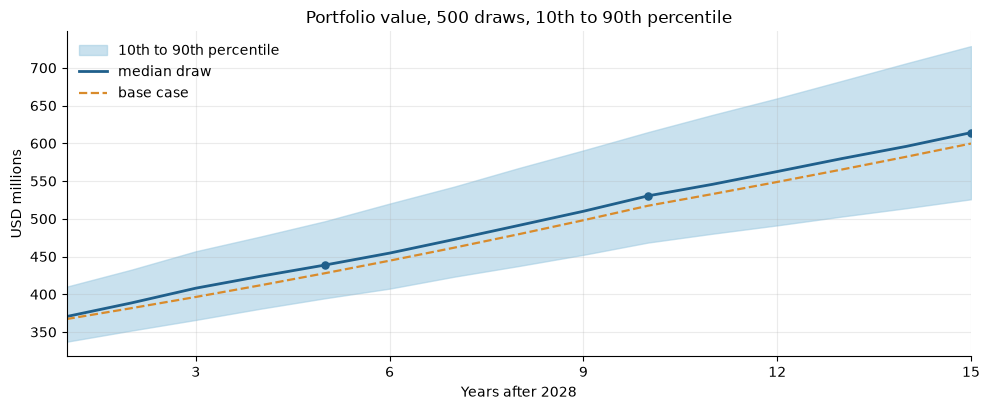

In [10]:
ax = plt.figure(figsize=(10, 4.2)).add_subplot()
ax.fill_between(band["year_index"], band["p10_musd"], band["p90_musd"],
                color="#9ecae1", alpha=0.55, label="10th to 90th percentile")
ax.plot(band["year_index"], band["p50_musd"], color="#1f5f8b", linewidth=2, label="median draw")
base_line = path[path["scenario"] == "base"].set_index("year_index")["value"] / 1e6
ax.plot(base_line.index, base_line, color="#d98b2b", linewidth=1.6,
        linestyle="--", label="base case")
ax.scatter(HORIZONS, [band.loc[band["year_index"] == year, "p50_musd"].iloc[0] for year in HORIZONS],
           color="#1f5f8b", s=26, zorder=3)
ax.set_title("Portfolio value, 500 draws, 10th to 90th percentile")
ax.set_xlabel("Years after " + str(BASE_YEAR))
ax.set_ylabel("USD millions")
ax.set_xticks(range(0, HORIZON + 1, 3))
ax.set_xlim(1, HORIZON)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


## Two levers, one grid

Year 10 value per room across ADR growth and occupancy drift, with the other
assumptions at base. Reading across a row shows what occupancy is worth at a
fixed rate path. Reading down a column shows what pricing is worth at a fixed
occupancy. Neither lever alone closes the gap between the downside and the
upside column of the horizon table.


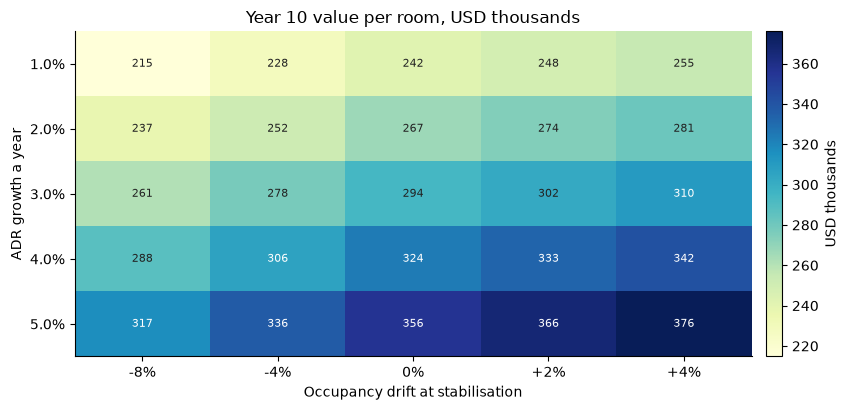

In [11]:
adr_growths = [0.010, 0.020, 0.030, 0.040, 0.050]
occupancy_drifts = [-0.080, -0.040, 0.000, 0.020, 0.040]
rooms_total = float(base["rooms"].sum())

grid = np.zeros((len(adr_growths), len(occupancy_drifts)))
for row, growth in enumerate(adr_growths):
    for column, drift in enumerate(occupancy_drifts):
        frame = project(growth=growth, occupancy_drift=drift, margin_gain=0.002,
                        cap_rate=0.075, years=10)
        grid[row, column] = frame.loc[frame["year_index"] == 10, "value"].sum() / rooms_total

figure, ax = plt.subplots(figsize=(8.6, 4.2))
image = ax.imshow(grid / 1000, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(occupancy_drifts)))
ax.set_xticklabels([format(value, "+.0%") if value else "0%" for value in occupancy_drifts])
ax.set_yticks(range(len(adr_growths)))
ax.set_yticklabels([format(value, ".1%") for value in adr_growths])
ax.set_xlabel("Occupancy drift at stabilisation")
ax.set_ylabel("ADR growth a year")
ax.set_title("Year 10 value per room, USD thousands")
cut = grid.min() + 0.55 * (grid.max() - grid.min())
for row in range(grid.shape[0]):
    for column in range(grid.shape[1]):
        ax.text(column, row, format(grid[row, column] / 1000, ".0f"),
                ha="center", va="center", fontsize=8,
                color="white" if grid[row, column] > cut else "#222222")
ax.grid(False)
figure.colorbar(image, ax=ax, fraction=0.03, pad=0.02, label="USD thousands")
plt.tight_layout()
plt.show()


## Where the value comes from

The bridge starts with today's rates held flat for fifteen years, then adds
inflation, the thin real ADR gain and the margin improvement in that order. It
ends on the base case, and the printed check confirms the end matches the
projection table. Most of the nominal growth is inflation. The real growth is
the small bar, which is the honest shape of a mature hotel asset.


bridge ends at 599.7 USD million, projection says 599.7


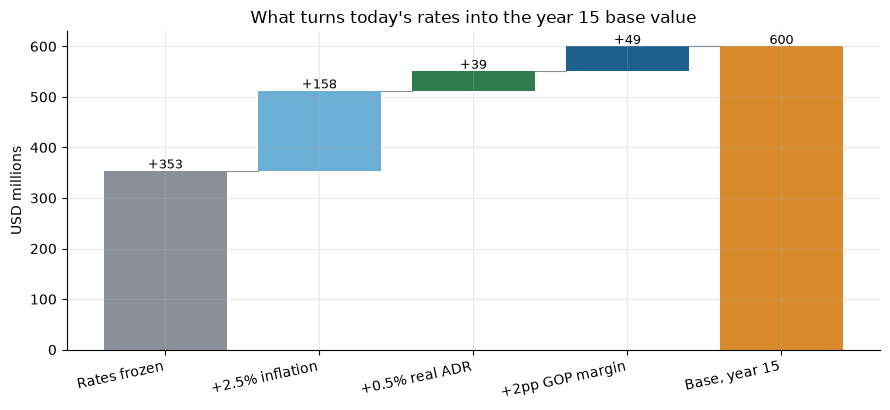

In [12]:
def terminal_value(growth: float, margin_gain: float = 0.0) -> float:
    frame = project(growth=growth, occupancy_drift=0.0, margin_gain=margin_gain,
                    cap_rate=ASSUMPTIONS["scenarios"]["base"]["cap_rate"])
    return float(frame.loc[frame["year_index"] == HORIZON, "value"].sum())


frozen = terminal_value(0.0)
inflation = terminal_value(ASSUMPTIONS["inflation"])
real = terminal_value(ASSUMPTIONS["scenarios"]["base"]["adr_growth"])
margin = terminal_value(ASSUMPTIONS["scenarios"]["base"]["adr_growth"],
                        ASSUMPTIONS["scenarios"]["base"]["margin_gain"])
check = float(projection.loc[(projection["scenario"] == "base")
                             & (projection["year_index"] == HORIZON), "value"].sum())

levels = [frozen, inflation, real, margin]
steps = [levels[0]] + [levels[index] - levels[index - 1] for index in range(1, len(levels))]
bottoms = [0] + levels[:-1]
names = ["Rates frozen", "+2.5% inflation", "+0.5% real ADR", "+2pp GOP margin"]
colors = ["#8a8f98", "#6baed6", "#2f7d4f", "#1f5f8b"]

figure, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(range(len(steps)), np.array(steps) / 1e6, bottom=np.array(bottoms) / 1e6, color=colors)
ax.bar(len(steps), margin / 1e6, color="#d98b2b")
for position, step in enumerate(steps):
    ax.text(position, (bottoms[position] + step) / 1e6 + 5, format(step / 1e6, "+.0f"),
            ha="center", fontsize=9)
ax.text(len(steps), margin / 1e6 + 5, format(margin / 1e6, ".0f"), ha="center", fontsize=9)
for position, level in enumerate(levels):
    ax.plot([position + 0.4, position + 1 - 0.4], [level / 1e6, level / 1e6],
            color="#8a8f98", linewidth=0.8)
ax.set_xticks(range(len(steps) + 1))
ax.set_xticklabels(names + ["Base, year " + str(HORIZON)], rotation=12, ha="right")
ax.set_ylabel("USD millions")
ax.set_title("What turns today's rates into the year 15 base value")
print("bridge ends at", round(margin / 1e6, 1), "USD million, projection says", round(check / 1e6, 1))
plt.tight_layout()
plt.show()


## Which hotels compound

The base case by hotel. Value CAGR is measured from year 1 to year 15, so it
excludes the first year's step. Bubble size is room count. The spread inside a
tier comes from the rate level, the margin and the review position, not from a
different growth assumption per hotel.


In [13]:
first = projection.loc[(projection["scenario"] == "base")
                       & (projection["year_index"] == 1)].set_index("hotel_id")
last = projection.loc[(projection["scenario"] == "base")
                      & (projection["year_index"] == HORIZON)].set_index("hotel_id")
hotel = base[["name", "tier", "rooms", "lifetime_rating"]].copy()
hotel["revpar_year_15"] = last["revpar"]
hotel["value_year_15"] = last["value"]
hotel["value_per_room_15"] = last["value_per_room"]
hotel["cagr"] = (last["value"] / first["value"]) ** (1 / (HORIZON - 1)) - 1

hotel.assign(cagr_pct=100 * hotel["cagr"])[
    ["name", "tier", "rooms", "lifetime_rating", "revpar_year_15",
     "value_year_15", "value_per_room_15", "cagr_pct"]
].sort_values("value_per_room_15", ascending=False).round(2)


,name,tier,rooms,lifetime_rating,revpar_year_15,value_year_15,value_per_room_15,cagr_pct
hotel_id,,,,,,,,
H03,Marisol Bay Resort,luxury,212,3.55,447.81,1.615639e+08,762093.89,3.46
H05,The Copper Meridian,luxury,96,3.57,399.68,6.309370e+07,657226.00,3.48
H02,The Lantern House,boutique,54,3.45,313.09,2.647593e+07,490295.05,3.53
H04,Harborlight Suites,upscale,140,3.32,293.45,5.381050e+07,384360.75,3.58
H01,Alder & Quay Hotel,upscale,168,3.51,270.30,6.376799e+07,379571.36,3.60
H07,The Wren Rooms,boutique,38,3.13,237.48,1.292429e+07,340112.93,3.49
H06,Seabright Grand,upscale,240,3.32,248.90,7.402586e+07,308441.06,3.62
H11,The Foxglove,boutique,44,3.39,214.88,1.298699e+07,295158.92,3.58
H14,Willowmere Lodge,upscale,104,3.26,231.08,3.002084e+07,288661.88,3.60


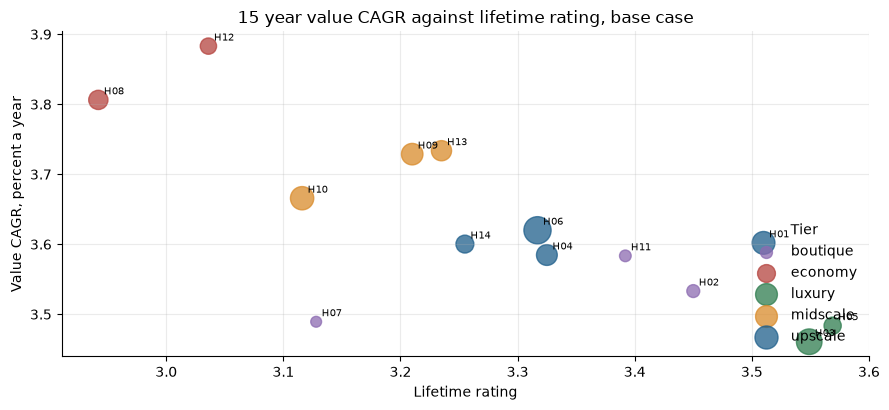

In [14]:
tier_colors = {"economy": "#b5443f", "midscale": "#d98b2b", "upscale": "#1f5f8b",
               "boutique": "#8c6bb1", "luxury": "#2f7d4f"}

figure, ax = plt.subplots(figsize=(9, 4.2))
for tier, group in hotel.groupby("tier"):
    ax.scatter(group["lifetime_rating"], 100 * group["cagr"], s=group["rooms"] * 1.6,
               color=tier_colors.get(tier, "#8a8f98"), alpha=0.75, label=tier)
for hotel_id, row in hotel.iterrows():
    ax.annotate(hotel_id, (row["lifetime_rating"], 100 * row["cagr"]), fontsize=7,
                xytext=(4, 4), textcoords="offset points")
ax.set_title("15 year value CAGR against lifetime rating, base case")
ax.set_xlabel("Lifetime rating")
ax.set_ylabel("Value CAGR, percent a year")
ax.legend(frameon=False, title="Tier", loc="lower right")
plt.tight_layout()
plt.show()


## Reading this page

The headline cell prints the three horizons in nominal, real and per room terms,
and states how much of the nominal gain is inflation. The honest reading is
usually that most of it is: a mature asset mostly keeps pace with prices unless
rate growth beats inflation.

Three habits keep a projection honest: keep the assumptions in one dictionary,
tie the bridge back to the table, and quote real and present values next to the
nominal ones. If the model is reused, change `ASSUMPTIONS` and rerun. Nothing
else in the notebook needs editing.

The last cell writes the full hotel-year table to `/kaggle/working` when the
notebook runs on Kaggle, so the projection can be downloaded and tested against
any model without rerunning the page.


In [15]:
summary = checkpoint(projection)
line = summary[summary["scenario"] == "base"].set_index("year")

print("Base case, portfolio value in USD millions")
for year_index in HORIZONS:
    row = line.loc[BASE_YEAR + year_index]
    print("  year {:2d}  nominal {:7.1f}   real {:7.1f}   per room {:>8,.0f}".format(
        year_index, row["value_musd"], row["value_real_musd"], row["value_per_room"]))
print("  frozen rates, year " + str(HORIZON) + ": "
      + format(frozen / 1e6, ".1f"))
print("  inflation share of the nominal gain: "
      + format((inflation - frozen) / (margin - frozen), ".0%"))


Base case, portfolio value in USD millions
  year  5  nominal   427.9   real   378.2   per room  243,122
  year 10  nominal   517.3   real   404.1   per room  293,904
  year 15  nominal   599.7   real   414.1   per room  340,735
  frozen rates, year 15: 353.4
  inflation share of the nominal gain: 64%


In [16]:
export = projection[["scenario", "year_index", "calendar_year", "hotel_id", "tier", "occupancy",
                     "adr", "revpar", "room_revenue", "total_revenue", "gop", "gop_margin",
                     "noi", "value", "value_real", "value_pv"]]
working = Path("/kaggle/working")
if working.exists():
    target = working / "nice-rooms-15y-projection.csv"
    export.to_csv(target, index=False)
    print("wrote " + str(target) + ", " + format(len(export), ",") + " rows")
export.head()


,scenario,year_index,calendar_year,hotel_id,tier,occupancy,adr,revpar,room_revenue,total_revenue,gop,gop_margin,noi,value,value_real,value_pv
0,downside,1,2029,H01,upscale,0.718572,238.324768,171.253486,1.050126e+07,1.235075e+07,3.647588e+06,0.295333,3.153558e+06,3.274160e+07,3.194302e+07,3.003817e+07
1,downside,1,2029,H02,boutique,0.736831,269.678724,198.707711,3.916529e+06,4.600405e+06,1.490267e+06,0.323943,1.306251e+06,1.374399e+07,1.340877e+07,1.260916e+07
2,downside,1,2029,H03,luxury,0.708027,402.841715,285.223006,2.207056e+07,2.610748e+07,9.023240e+06,0.345619,7.978941e+06,8.465549e+07,8.259072e+07,7.766558e+07
3,downside,1,2029,H04,upscale,0.729293,256.637833,187.164194,9.564090e+06,1.101316e+07,3.124696e+06,0.283724,2.684170e+06,2.769147e+07,2.701607e+07,2.540502e+07
4,downside,1,2029,H05,luxury,0.698448,364.089551,254.297651,8.910590e+06,1.056357e+07,3.538967e+06,0.335016,3.116425e+06,3.293550e+07,3.213219e+07,3.021605e+07
